<a href="https://colab.research.google.com/github/cjas65929-lang/Proyecto-Pterigion-CNN/blob/main/Modelo_Pterigion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
--------------------------------------------------------------------------------------------- EXPLICACION DEL CODIGO -------------------------------------------------------------------------------------------------
El código primero indica dónde están las imágenes para entrenar y probar el modelo, define el tamaño que tendrán, cuántas clases existen (del grado 0 al 4) y cuántas imágenes se procesarán por grupo.
Luego prepara las imágenes aplicando ajustes como rotaciones, zoom o volteos para que el modelo aprenda a reconocer el pterigium en distintas posiciones.
Después construye una red neuronal con varias capas que analizarán las imágenes y aprenderán a identificar las diferencias entre cada grado.
El modelo se compila, se entrena durante 100 épocas con los datos preparados, y al finalizar se evalúa para saber qué tan preciso fue en sus predicciones.
Una vez validado, se guarda en un archivo para reutilizarlo sin volver a entrenar. Finalmente, la función de predicción permite analizar una imagen nueva, procesarla igual que las anteriores y mostrar el grado de pterigium correspondiente junto con un mensaje descriptivo.
"""

'\n--------------------------------------------------------------------------------------------- EXPLICACION DEL CODIGO -------------------------------------------------------------------------------------------------\nEl código primero indica dónde están las imágenes para entrenar y probar el modelo, define el tamaño que tendrán, cuántas clases existen (del grado 0 al 4) y cuántas imágenes se procesarán por grupo.\nLuego prepara las imágenes aplicando ajustes como rotaciones, zoom o volteos para que el modelo aprenda a reconocer el pterigium en distintas posiciones.\nDespués construye una red neuronal con varias capas que analizarán las imágenes y aprenderán a identificar las diferencias entre cada grado.\nEl modelo se compila, se entrena durante 100 épocas con los datos preparados, y al finalizar se evalúa para saber qué tan preciso fue en sus predicciones.\nUna vez validado, se guarda en un archivo para reutilizarlo sin volver a entrenar. Finalmente, la función de predicción permite

In [ ]:
#Importamos las librerias
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
import cv2

In [ ]:
#Realizamos las rutas del datasets de Entrenamiento y Prueba
train_dir = "/content/drive/MyDrive/dataset/train"
test_dir = "/content/drive/MyDrive/dataset/test"
img_size = (224, 224)
batch_size = 32
num_classes = 5

# Realizamos un preprocesamiento de los datos
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="training"
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="validation"
)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

# Cargamos MobileNetV2 sin la capa final
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Congelamos sus pesos para que no se reentrene
base_model.trainable = False

# Añadimos capas finales personalizadas
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compilamos el modelo
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

#Realizamos el Entrenamiento del Modelo con 100 Epocas
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=100
)

#Realizamos una evaluacion
test_loss, test_acc = model.evaluate(test_generator)
print(f"Precisión en el conjunto de prueba: {test_acc:.2f}")

#Guardamos el Modelo
model.save("modelo_pterygium_mobilenetv4.h5")
print("Modelo guardado")


def predecir_imagen(ruta_imagen):
    imagen = cv2.imread(ruta_imagen)
    imagen = cv2.resize(imagen, img_size)
    imagen = np.expand_dims(imagen, axis=0)
    imagen = preprocess_input(imagen)

    prediccion = model.predict(imagen)
    clase_predicha = np.argmax(prediccion)

    mensajes = {
        0: "Grado 0: Ojo sin pterigión o normal.",
        1: "Grado 1: Aparición leve entre el limbo y el margen de la pupila.",
        2: "Grado 2: Empieza a invadir el margen pupilar.",
        3: "Grado 3: Afecta completamente la pupila causando visión borrosa y molestias intensas.",
        4: "Grado 4: El pterigión invade más allá de la pupila."
    }

    print(f"Predicción: {mensajes[clase_predicha]}")
    return clase_predicha

Found 481 images belonging to 5 classes.
Found 118 images belonging to 5 classes.
Found 153 images belonging to 5 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 119s 7s/step - accuracy: 0.3169 - loss: 1.8983 - val_accuracy: 0.3983 - val_loss: 1.4789
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.4032 - loss: 1.5943 - val_accuracy: 0.4661 - val_loss: 1.3560
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.4182 - loss: 1.4713 - val_accuracy: 0.5000 - val_loss: 1.2598
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.4698 - loss: 1.3495 - val_accuracy: 0.5085 - val_loss: 1.1640
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.5009 - loss: 1.2634 - val_accuracy: 0.5593 - val_loss: 1.1313
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.4891 - loss: 1.2571 - val_accuracy: 0.5847 - val_loss: 1.0268
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.5829 - loss: 1.1298 - val_accuracy: 0.6695 - val_loss: 0.9895
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.6103 - loss: 1.0642 - val_accuracy: 0.6441 - 

Precisión en el conjunto de prueba: 0.80
Modelo guardado


In [ ]:
import h5py

ruta = "/content/modelo_pterygium_mobilenetv3.h5"

with h5py.File(ruta, "r") as f:
    if "keras_version" in f.attrs:
        print("Versión de Keras usada para guardarlo:", f.attrs["keras_version"])
    else:
        print("No se encontró versión de Keras en atributos.")


Versión de Keras usada para guardarlo: 3.10.0


Cargando modelo...


✅ Modelo cargado correctamente
Found 172 images belonging to 5 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Realizando predicciones...
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step

📊 MATRIZ DE CONFUSIÓN
[[40  0  0  0  0]
 [ 1  8 10  0  1]
 [ 0  1 63  0  5]
 [ 1  5  7  5  3]
 [ 0  0  9  0 13]]


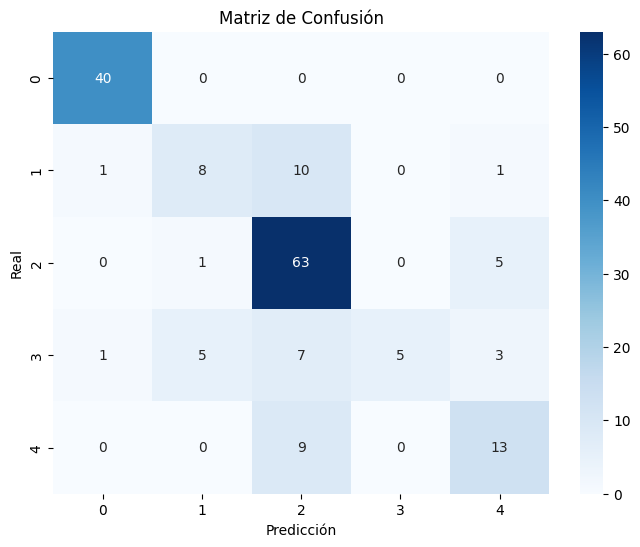


🧾 REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        40
           1       0.57      0.40      0.47        20
           2       0.71      0.91      0.80        69
           3       1.00      0.24      0.38        21
           4       0.59      0.59      0.59        22

    accuracy                           0.75       172
   macro avg       0.76      0.63      0.64       172
weighted avg       0.77      0.75      0.72       172



In [ ]:
# ===========================
#  EVALUACIÓN DE MODELO CNN
# ===========================

import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------
# CONFIGURACIÓN
# ---------------------------
modelo_ruta = "/content/modelo_pterygium_mobilenetv3.h5"   # Ruta a tu modelo
ruta_test = "/content/drive/MyDrive/dataset/test"  # Carpeta de test
img_size = (224, 224)                             # Tamaño de imagen (igual que entrenamiento)
batch_size = 32


# ---------------------------
# CARGAR EL MODELO
# ---------------------------
print("Cargando modelo...")
model = tf.keras.models.load_model(modelo_ruta)
print("✅ Modelo cargado correctamente")

# ---------------------------
# PREPARAR DATOS DE TEST
# ---------------------------
datagen = ImageDataGenerator(rescale=1.0/255)

test_data = datagen.flow_from_directory(
    ruta_test,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# ---------------------------
# REALIZAR PREDICCIONES
# ---------------------------
print("Realizando predicciones...")
predicciones = model.predict(test_data)
y_pred = np.argmax(predicciones, axis=1)
y_true = test_data.classes
clases = list(test_data.class_indices.keys())

# ---------------------------
# MOSTRAR RESULTADOS
# ---------------------------
print("\n📊 MATRIZ DE CONFUSIÓN")
cm = confusion_matrix(y_true, y_pred)
print(cm)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

# ---------------------------
# REPORTE DE CLASIFICACIÓN
# ---------------------------
print("\n🧾 REPORTE DE CLASIFICACIÓN")
print(classification_report(y_true, y_pred, target_names=clases))


In [ ]:
import gradio as gr
print(gr.__version__)

5.50.0


In [ ]:
#Importamos las librerias
!pip install tensorflow gradio opencv-python --quiet

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
import cv2
import gradio as gr

#Realizamos el cargado del modelo entrenado
modelo_ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"  # Subir antes de ejecutar
#model = tf.keras.models.load_model(modelo_ruta)
model = tf.keras.models.load_model(
    modelo_ruta,
    compile=False,
    safe_mode=False
)

#Configuramos los parametros
img_size = (224, 224)
mensajes = {
    0: "Grado 0: Ojo sin pterigión o normal.",
    1: "Grado 1: Aparición leve entre el limbo y el margen de la pupila.",
    2: "Grado 2: Empieza a invadir el margen pupilar.",
    3: "Grado 3: Afecta completamente la pupila causando visión borrosa y molestias intensas.",
    4: "Grado 4: El pterigión invade más allá de la pupila."
}

# Creamos una funcion para predecir la imagen que se analice
def predecir_imagen(imagen):
    imagen = cv2.cvtColor(np.array(imagen), cv2.COLOR_RGB2BGR)
    imagen = cv2.resize(imagen, img_size)
    imagen = np.expand_dims(imagen, axis=0)
    imagen = preprocess_input(imagen)
    prediccion = model.predict(imagen)
    clase_predicha = np.argmax(prediccion)
    probabilidad = np.max(prediccion) * 100
    return f"{mensajes[clase_predicha]} (Confianza: {probabilidad:.2f}%)"

# Realizamos la interfaz de Gradio
interfaz = gr.Interface(
    fn=predecir_imagen,
    inputs=gr.Image(type="pil", label="Sube una imagen del ojo"),
    outputs=gr.Textbox(label="Resultado del diagnóstico"),
    title="Detección de Pterigión",
    description="Sube una imagen del ojo y el modelo clasificará el grado del pterigión (0 a 4).",
    theme="gradio/soft"
)

# Levantamos la interfaz de Gradio
interfaz.launch(share=True)

ValueError: Layer "dense" expects 1 input(s), but it received 2 input tensors. Inputs received: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_328>, <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_329>]

In [ ]:
import h5py
import json
import os

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

print("=" * 50)
print("INFORMACIÓN DEL ARCHIVO")
print("=" * 50)

if os.path.exists(ruta):

    print(f"Tamaño: {os.path.getsize(ruta)/1024/1024:.2f} MB")

    with h5py.File(ruta, "r") as f:

        print("\nKEYS:")
        print(list(f.keys()))

        print("\nATRIBUTOS:")
        print(list(f.attrs.keys()))

        if "model_config" in f.attrs:

            print("\nMODELO COMPLETO DETECTADO")

            try:
                config = json.loads(f.attrs["model_config"])

                print("Clase:", config.get("class_name"))

                if "config" in config:
                    layers = config["config"].get("layers", [])
                    print("Número de capas:", len(layers))

                    print("\nPrimeras capas:")

                    for layer in layers[:10]:
                        print(
                            f" - {layer.get('class_name')}: "
                            f"{layer.get('config', {}).get('name', 'sin_nombre')}"
                        )

            except Exception as e:
                print("Error leyendo model_config:")
                print(e)

        else:
            print("\nNO SE ENCONTRÓ model_config")
            print("Probablemente son solo pesos.")

        print("\nCONTENIDO DETALLADO:")

        def recorrer(nombre, obj):
            print(nombre)

        f.visititems(recorrer)

else:
    print("No se encontró el archivo.")

INFORMACIÓN DEL ARCHIVO
Tamaño: 10.85 MB

KEYS:
['model_weights', 'optimizer_weights']

ATRIBUTOS:
['backend', 'keras_version', 'model_config', 'training_config']

MODELO COMPLETO DETECTADO
Clase: Sequential
Número de capas: 6

Primeras capas:
 - InputLayer: input_layer_1
 - Functional: mobilenetv2_1.00_224
 - GlobalAveragePooling2D: global_average_pooling2d
 - Dropout: dropout
 - Dense: dense
 - Dense: dense_1

CONTENIDO DETALLADO:
model_weights
model_weights/dense
model_weights/dense/sequential
model_weights/dense/sequential/dense
model_weights/dense/sequential/dense/bias
model_weights/dense/sequential/dense/kernel
model_weights/dense_1
model_weights/dense_1/sequential
model_weights/dense_1/sequential/dense_1
model_weights/dense_1/sequential/dense_1/bias
model_weights/dense_1/sequential/dense_1/kernel
model_weights/dropout
model_weights/global_average_pooling2d
model_weights/mobilenetv2_1.00_224
model_weights/mobilenetv2_1.00_224/Conv1
model_weights/mobilenetv2_1.00_224/Conv1/kernel


In [ ]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.20.0
Keras: 3.13.2


In [ ]:
import os

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

print("Tamaño:", os.path.getsize(ruta)/1024/1024, "MB")

Tamaño: 10.8529052734375 MB


In [ ]:
import h5py

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

with h5py.File(ruta, "r") as f:
    print("Keras original:", f.attrs["keras_version"])
    print("Backend:", f.attrs["backend"])

Keras original: 3.10.0
Backend: tensorflow


In [ ]:
!pip uninstall -y keras tensorflow
!pip install keras==3.10.0 tensorflow==2.19.0

Found existing installation: keras 3.13.2
Uninstalling keras-3.13.2:
  Successfully uninstalled keras-3.13.2
Found existing installation: tensorflow 2.20.0
Uninstalling tensorflow-2.20.0:
  Successfully uninstalled tensorflow-2.20.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 851.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 493.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 635.9 kB/s eta 0:00:00
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.20.0
    Uninstalling tensorboard-2.20.0:
      Successfully uninstalled tensorboard-2.20.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.19.0 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2

In [ ]:
# ACTUALIZACIÓN DE DEPENDENCIAS

In [ ]:
import tensorflow as tf
import keras
import h5py

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("h5py:", h5py.__version__)

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

with h5py.File(ruta, "r") as f:
    print("\nClaves:", list(f.keys()))
    print("Atributos:", list(f.attrs.keys()))

    if "model_config" in f.attrs:
        print("\nEl archivo contiene model_config.")
    else:
        print("\nEl archivo no contiene model_config.")

TensorFlow: 2.21.0
Keras: 3.13.2
h5py: 3.14.0

Claves: ['model_weights', 'optimizer_weights']
Atributos: ['backend', 'keras_version', 'model_config', 'training_config']

El archivo contiene model_config.


In [ ]:
import h5py
import json

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

with h5py.File(ruta, "r") as f:
    print("Backend original:", f.attrs.get("backend"))
    print("Versión Keras original:", f.attrs.get("keras_version"))

    raw = f.attrs["model_config"]
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8")

    config = json.loads(raw)

print("\nClase del modelo:", config.get("class_name"))

def inspeccionar_capas(obj):
    if isinstance(obj, dict):
        nombre = obj.get("config", {}).get("name", "")

        if obj.get("class_name") in ("Dense", "Flatten", "GlobalAveragePooling2D"):
            print("\nClase:", obj.get("class_name"))
            print("Nombre:", nombre)
            print("Configuración:", obj.get("config"))
            print("Conexiones:", obj.get("inbound_nodes"))

        for valor in obj.values():
            inspeccionar_capas(valor)

    elif isinstance(obj, list):
        for valor in obj:
            inspeccionar_capas(valor)

inspeccionar_capas(config)


Backend original: tensorflow
Versión Keras original: 3.10.0

Clase del modelo: Sequential

Clase: GlobalAveragePooling2D
Nombre: global_average_pooling2d
Configuración: {'name': 'global_average_pooling2d', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'keepdims': False}
Conexiones: None

Clase: Dense
Nombre: dense
Configuración: {'name': 'dense', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 128, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_co

In [ ]:
import h5py
import json

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

with h5py.File(ruta, "r") as f:
    raw = f.attrs["model_config"]
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8")
    config = json.loads(raw)

cfg = config.get("config", {})

print("Clase:", config.get("class_name"))
print("Configuración de construcción:", cfg.get("build_config"))
print("Número de capas:", len(cfg.get("layers", [])))

for i, layer in enumerate(cfg.get("layers", [])):
    lc = layer.get("config", {})
    print(f"\n--- Capa {i} ---")
    print("Clase:", layer.get("class_name"))
    print("Nombre:", lc.get("name"))
    print("Entrada:", lc.get("batch_input_shape",
                           lc.get("input_shape")))
    print("Configuración de construcción:",
          layer.get("build_config"))
    print("Conexiones:", layer.get("inbound_nodes"))

    if layer.get("class_name") == "Functional":
        print("Modelo funcional anidado detectado")
    elif layer.get("class_name") == "Model":
        print("Modelo anidado detectado")


Clase: Sequential
Configuración de construcción: None
Número de capas: 6

--- Capa 0 ---
Clase: InputLayer
Nombre: input_layer_1
Entrada: None
Configuración de construcción: None
Conexiones: None

--- Capa 1 ---
Clase: Functional
Nombre: mobilenetv2_1.00_224
Entrada: None
Configuración de construcción: None
Conexiones: None
Modelo funcional anidado detectado

--- Capa 2 ---
Clase: GlobalAveragePooling2D
Nombre: global_average_pooling2d
Entrada: None
Configuración de construcción: None
Conexiones: None

--- Capa 3 ---
Clase: Dropout
Nombre: dropout
Entrada: None
Configuración de construcción: None
Conexiones: None

--- Capa 4 ---
Clase: Dense
Nombre: dense
Entrada: None
Configuración de construcción: None
Conexiones: None

--- Capa 5 ---
Clase: Dense
Nombre: dense_1
Entrada: None
Configuración de construcción: None
Conexiones: None


In [ ]:
import h5py
import json

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

with h5py.File(ruta, "r") as f:
    raw = f.attrs["model_config"]
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8")
    config = json.loads(raw)

capas = config["config"]["layers"]

for capa in capas:
    if capa.get("class_name") == "Functional":
        print("MODELO INTERNO:", capa["config"].get("name"))

        internas = capa["config"].get("layers", [])
        print("Número de capas internas:", len(internas))

        for interna in internas[-8:]:
            c = interna.get("config", {})
            print(
                interna.get("class_name"),
                c.get("name"),
                "configuración:",
                interna.get("build_config")
            )

        print("\nConfiguración de salida:")
        print(capa["config"].get("output_layers"))


MODELO INTERNO: mobilenetv2_1.00_224
Número de capas internas: 154
DepthwiseConv2D block_16_depthwise configuración: None
BatchNormalization block_16_depthwise_BN configuración: None
ReLU block_16_depthwise_relu configuración: None
Conv2D block_16_project configuración: None
BatchNormalization block_16_project_BN configuración: None
Conv2D Conv_1 configuración: None
BatchNormalization Conv_1_bn configuración: None
ReLU out_relu configuración: None

Configuración de salida:
[['out_relu', 0, 0]]


In [ ]:
import sys
print(sys.version)


3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
%pip install -q keras==3.10.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-hub 0.26.0 requires keras>=3.13, but you have keras 3.10.0 which is incompatible.
tensorflow 2.21.0 requires keras>=3.12.0, but you have keras 3.10.0 which is incompatible.


In [ ]:
%pip install -q keras==3.13.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 4.8 MB/s eta 0:00:00


In [ ]:
import sys
import tensorflow as tf
import keras

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
Keras: 3.13.2


In [ ]:
%pip install tf-keras

In [ ]:
import h5py
import numpy as np
import keras
from keras import Sequential
from keras.layers import Input, GlobalAveragePooling2D, Dropout, Dense
from keras.applications import MobileNetV2

ruta = "/content/drive/MyDrive/modelo_pterygium_mobilenetv4.h5"

# 1. Reconstruir la arquitectura original
base = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights=None
)
base.trainable = False

modelo = Sequential([
    Input(shape=(224, 224, 3)),
    base,
    GlobalAveragePooling2D(),
    Dropout(0.4),
    Dense(128, activation="relu", name="dense"),
    Dense(5, activation="softmax", name="dense_1")
])

# Crear todas las variables del modelo
modelo(np.zeros((1, 224, 224, 3), dtype=np.float32))

# 2. Leer los pesos guardados
with h5py.File(ruta, "r") as f:
    datasets = {}

    def recoger(nombre, objeto):
        if isinstance(objeto, h5py.Dataset):
            datasets[nombre] = objeto[...]

    f["model_weights"].visititems(recoger)

    capas = list(base.layers) + [
        modelo.get_layer("dense"),
        modelo.get_layer("dense_1")
    ]

    asignados = 0
    faltantes = []

    for capa in capas:
        for variable in capa.weights:
            nombre_variable = getattr(
                variable, "path", variable.name
            ).split("/")[-1]

            candidatos = [
                (ruta_peso, valor)
                for ruta_peso, valor in datasets.items()
                if capa.name in ruta_peso.split("/")
                and ruta_peso.split("/")[-1] == nombre_variable
            ]

            compatibles = [
                (ruta_peso, valor)
                for ruta_peso, valor in candidatos
                if tuple(valor.shape) == tuple(variable.shape)
            ]

            if len(compatibles) == 1:
                variable.assign(compatibles[0][1])
                asignados += 1
            else:
                faltantes.append({
                    "capa": capa.name,
                    "variable": nombre_variable,
                    "forma_esperada": tuple(variable.shape),
                    "coincidencias": len(compatibles)
                })

print("Variables asignadas:", asignados)
print("Variables sin coincidencia única:", len(faltantes))

if faltantes:
    print("Detalles:", faltantes[:15])
else:
    print("¡Todos los pesos encontrados y asignados!")
    modelo.save(
        "/content/drive/MyDrive/modelo_pterygium_recuperado.keras"
    )
    print("Modelo guardado correctamente.")

Variables asignadas: 264
Variables sin coincidencia única: 0
¡Todos los pesos encontrados y asignados!
Modelo guardado correctamente.


In [ ]:
import keras
import numpy as np

ruta_modelo = "/content/drive/MyDrive/modelo_pterygium_recuperado.keras"

modelo = keras.models.load_model(ruta_modelo, compile=False)

print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

# Prueba técnica con una entrada ficticia
prueba = np.zeros((1, 224, 224, 3), dtype=np.float32)
prediccion = modelo.predict(prueba, verbose=0)

print("Predicciones:", prediccion)
print("Suma de probabilidades:", prediccion.sum())
print("Clase predicha:", np.argmax(prediccion, axis=1)[0])

Entrada: (None, 224, 224, 3)
Salida: (None, 5)
Predicciones: [[0.04648501 0.08149642 0.5060543  0.13861091 0.2273533 ]]
Suma de probabilidades: 0.9999999
Clase predicha: 2


In [ ]:

# ============================================
# DETECCIÓN Y CLASIFICACIÓN DE PTERIGIÓN
# Modelo MobileNetV2 recuperado
# ============================================

# 1. INSTALAR LIBRERÍAS
!pip install -q gradio opencv-python

# 2. IMPORTAR LIBRERÍAS
import os
import numpy as np
import keras
import gradio as gr
from PIL import Image
from keras.applications.mobilenet_v2 import preprocess_input

# ============================================
# 3. CONECTAR GOOGLE DRIVE
# ============================================

from google.colab import drive
drive.mount("/content/drive")

# ============================================
# 4. CARGAR EL MODELO RECONSTRUIDO
# ============================================

modelo_ruta = "/content/drive/MyDrive/modelo_pterygium_recuperado.keras"

if not os.path.exists(modelo_ruta):
    raise FileNotFoundError(
        f"No se encontró el modelo: {modelo_ruta}"
    )

model = keras.models.load_model(
    modelo_ruta,
    compile=False
)

print("Modelo cargado correctamente")
print("Entrada:", model.input_shape)
print("Salida:", model.output_shape)

# Verificar dimensiones esperadas
if model.output_shape[-1] != 5:
    raise ValueError("El modelo no tiene las 5 clases esperadas.")

# ============================================
# 5. CONFIGURACIÓN
# ============================================

img_size = (224, 224)

mensajes = {
    0: "Grado 0: Ojo sin pterigión o normal.",
    1: "Grado 1: Aparición leve entre el limbo y el margen de la pupila.",
    2: "Grado 2: Empieza a invadir el margen pupilar.",
    3: "Grado 3: Afectación extensa de la pupila.",
    4: "Grado 4: Pterigión que invade más allá de la pupila."
}

# ============================================
# 6. FUNCIÓN DE PREDICCIÓN
# ============================================

def predecir_imagen(imagen):

    if imagen is None:
        return "Por favor, sube una imagen del ojo."

    try:
        # Convertir a RGB
        imagen = imagen.convert("RGB")

        # Redimensionar
        imagen = imagen.resize(img_size)

        # Convertir a arreglo NumPy
        imagen = np.array(imagen, dtype=np.float32)

        # Preprocesamiento de MobileNetV2
        imagen = preprocess_input(imagen)

        # Crear lote de una imagen
        imagen = np.expand_dims(imagen, axis=0)

        # Predecir
        prediccion = model.predict(imagen, verbose=0)[0]

        # Clase con mayor probabilidad
        clase = int(np.argmax(prediccion))
        confianza = float(prediccion[clase]) * 100

        # Mostrar todas las probabilidades
        detalle = "\n".join(
            f"Grado {i}: {float(p) * 100:.2f}%"
            for i, p in enumerate(prediccion)
        )

        return (
            f"{mensajes[clase]}\n\n"
            f"Clase estimada: {clase}\n"
            f"Probabilidad máxima: {confianza:.2f}%\n\n"
            f"Probabilidades por clase:\n{detalle}\n\n"
            "Aviso: resultado experimental; no sustituye "
            "la evaluación de un oftalmólogo."
        )

    except Exception as e:
        return f"Error al procesar la imagen: {str(e)}"

# ============================================
# 7. INTERFAZ DE GRADIO
# ============================================

interfaz = gr.Interface(
    fn=predecir_imagen,
    inputs=gr.Image(
        type="pil",
        label="Sube una fotografía del ojo"
    ),
    outputs=gr.Textbox(
        label="Resultado de la clasificación",
        lines=12
    ),
    title="Detección y clasificación de pterigión",
    description=(
        "Carga una fotografía para obtener la clase estimada "
        "por el modelo MobileNetV2, de grado 0 a grado 4."
    ),
    theme="soft"
)

# ============================================
# 8. INICIAR LA APLICACIÓN
# ============================================

interfaz.launch(share=True)



Mounted at /content/drive
Modelo cargado correctamente
Entrada: (None, 224, 224, 3)
Salida: (None, 5)


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8b09c7e65e545d9a2f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ============================================
# DETECCIÓN DE PRESENCIA DE PTERIGIÓN
# ============================================
import gradio as gr
def predecir_imagen(imagen):
    if imagen is None:
        return "Por favor, sube una imagen del ojo."

    try:
        imagen = imagen.convert("RGB")
        imagen = imagen.resize((224, 224))

        imagen = np.array(imagen, dtype=np.float32)
        imagen = preprocess_input(imagen)
        imagen = np.expand_dims(imagen, axis=0)

        prediccion = model.predict(imagen, verbose=0)[0]

        # Clase 0 = ausencia; clases 1-4 = presencia
        probabilidad_sin = float(prediccion[0])
        probabilidad_con = float(np.sum(prediccion[1:]))

        if np.argmax(prediccion) == 0:
            resultado = "PTERIGIÓN NO DETECTADO"
        else:
            resultado = "PTERIGIÓN DETECTADO"

        return (
            f"{resultado}\n\n"
            f"Probabilidad estimada de presencia: "
            f"{probabilidad_con * 100:.2f}%\n"
            f"Probabilidad estimada de ausencia: "
            f"{probabilidad_sin * 100:.2f}%"
        )

    except Exception as e:
        return f"Error al procesar la imagen: {str(e)}"


# ============================================
# INTERFAZ DE GRADIO
# ============================================

interfaz = gr.Interface(
    fn=predecir_imagen,
    inputs=gr.Image(
        type="pil",
        label="Sube una fotografía del ojo"
    ),
    outputs=gr.Textbox(
        label="Resultado de detección",
        lines=4
    ),
    title="Detección de Pterigión",
    description=(
        "Carga una fotografía del ojo para obtener una "
        "estimación de presencia o ausencia de pterigión."
    ),
    theme="soft"
)

interfaz.launch(share=True)


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cfb12b1d97cde3ff01.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
